# 🚗 Vehicle Sales: Cleaning & Charts with matplotlib + seaborn
**Data Analytics Career Bootcamp · Class 16 companion notebook** | Instructor: Md. Rahat Anwar Khan

Dataset: [Vehicle Sales Data (Kaggle)](https://www.kaggle.com/datasets/syedanwarafridi/vehicle-sales-data) - 558,837 used-vehicle auction sales (`car_prices.csv`).

| Part | What you will do | Class 16 slide |
|---|---|---|
| **1. Load & first look** | load the CSV, run the first-look commands | Pandas review |
| **2. Clean** | the 4 C's: Convert, Correct, Complete, Create | Pandas review |
| **3. matplotlib charts** | bar, line, histogram, multi-panel | Chart selection · Chart hygiene |
| **4. seaborn charts** | box, scatter, line, heatmap, histogram | Chart selection · Libraries |
| **5. Insights & save** | write takeaways, export the clean file for the Streamlit app | Portfolio blueprint |

**How to use:** Colab → *File → Upload notebook* → run top to bottom with `Shift + Enter`. When asked, upload `car_prices.csv` (the `.zip` works too).

> **Chart hygiene rules used in every chart (slide 7):** the **title states the takeaway**, every axis has a label and unit, bars are **sorted**, colour is limited, and **one key bar is highlighted in crimson**.

## Part 1 - Setup, load and first look

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

# one small palette for the whole notebook: grey for context, crimson for the point we want you to see
CRIMSON, MUTED, PRIMARY = "#DC143C", "#9AA5B1", "#1F4E79"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
})

money = mtick.FuncFormatter(lambda x, _: f"${x:,.0f}")      # 12000 -> $12,000
thousands = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")   # 12000 -> 12,000

os.makedirs("charts", exist_ok=True)
def save(fig, name):
    """Save a PNG you can drop into your portfolio README."""
    fig.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")

In [3]:
# Find the file next to the notebook; in Colab, ask for an upload
candidates = ["car_prices.csv", "car_prices.csv.zip", "data/car_prices.csv"]
path = next((p for p in candidates if os.path.exists(p)), None)

if path is None:
    try:
        from google.colab import files           # only exists inside Colab
        print("Upload car_prices.csv (or car_prices.csv.zip):")
        path = list(files.upload())[0]
    except ImportError:
        raise FileNotFoundError("Put car_prices.csv in the same folder as this notebook and run again.")

raw = pd.read_csv(path)                           # .zip works too if it holds one CSV
print(f"Loaded {path}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Loaded car_prices.csv: 558,837 rows x 16 columns


,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.00,"16,639.00",white,black,kia motors america inc,"20,500.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.00,"9,393.00",white,beige,kia motors america inc,"20,800.00","21,500.00",Tue Dec 16 2014 12:30:00 GMT-0800 (PST)
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.00,"1,331.00",gray,black,financial services remarketing (lease),"31,900.00","30,000.00",Thu Jan 15 2015 04:30:00 GMT-0800 (PST)
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.00,"14,282.00",white,black,volvo na rep/world omni,"27,500.00","27,750.00",Thu Jan 29 2015 04:30:00 GMT-0800 (PST)
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.00,"2,641.00",gray,black,financial services remarketing (lease),"66,000.00","67,000.00",Thu Dec 18 2014 12:30:00 GMT-0800 (PST)


### The five first-look commands (Class 14)

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   year          558837 non-null  int64  
 1   make          548536 non-null  str    
 2   model         548438 non-null  str    
 3   trim          548186 non-null  str    
 4   body          545642 non-null  str    
 5   transmission  493485 non-null  str    
 6   vin           558833 non-null  str    
 7   state         558837 non-null  str    
 8   condition     547017 non-null  float64
 9   odometer      558743 non-null  float64
 10  color         558088 non-null  str    
 11  interior      558088 non-null  str    
 12  seller        558837 non-null  str    
 13  mmr           558799 non-null  float64
 14  sellingprice  558825 non-null  float64
 15  saledate      558825 non-null  str    
dtypes: float64(4), int64(1), str(11)
memory usage: 132.9 MB


In [5]:
# share of missing values per column, worst first
(raw.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("missing %")

,missing %
transmission,11.70
body,2.40
condition,2.10
trim,1.90
model,1.90
make,1.80
color,0.10
interior,0.10
state,0.00
vin,0.00


In [6]:
raw.describe()

,year,condition,odometer,mmr,sellingprice
count,"558,837.00","547,017.00","558,743.00","558,799.00","558,825.00"
mean,"2,010.04",30.67,"68,320.02","13,769.38","13,611.36"
std,3.97,13.40,"53,398.54","9,679.97","9,749.50"
min,"1,982.00",1.00,1.00,25.00,1.00
25%,"2,007.00",23.00,"28,371.00","7,100.00","6,900.00"
50%,"2,012.00",35.00,"52,254.00","12,250.00","12,100.00"
75%,"2,013.00",42.00,"99,109.00","18,300.00","18,200.00"
max,"2,015.00",49.00,"999,999.00","182,000.00","230,000.00"


### 🔍 What's wrong with this data?
Always look for problems *before* cleaning. Each line below is a real issue in the raw file.

In [7]:
print("1) Same make spelled several ways:")
print(f"   {raw['make'].nunique()} distinct make values, but only {raw['make'].str.strip().str.lower().nunique()} after lower-casing")
print("   examples:", raw["make"].dropna().loc[lambda s: s.str.lower().isin(["ford", "vw", "volkswagen", "mercedes-b", "chev truck"])].unique().tolist())

print("\n2) Body type in mixed case:", raw["body"].dropna().loc[lambda s: s.str.lower() == "suv"].unique().tolist())

print("\n3) Odd values in `transmission`:", raw["transmission"].value_counts().to_dict())

print(f"\n4) `state` should have ~50 codes but has {raw['state'].nunique()} distinct values; junk looks like:",
      raw["state"][raw["state"].str.len() > 2].head(2).tolist())

print("\n5) `condition` mixes two scales (1-5 and 11-49):")
print("   ", [int(v) for v in sorted(raw["condition"].dropna().unique())[:12]], "...")

print(f"\n6) Placeholder odometer values: {(raw['odometer'] >= 500_000).sum()} rows at 500,000+ miles (max {raw['odometer'].max():,.0f})")
print(f"   Selling price under $500: {(raw['sellingprice'] < 500).sum():,} rows (min ${raw['sellingprice'].min():,.0f})")

print("\n7) `saledate` is text, not a date:", raw["saledate"].iloc[0])

1) Same make spelled several ways:
   96 distinct make values, but only 66 after lower-casing
   examples: ['Ford', 'Volkswagen', 'ford', 'volkswagen', 'mercedes-b', 'vw', 'chev truck']

2) Body type in mixed case: ['SUV', 'suv']

3) Odd values in `transmission`: {'automatic': 475915, 'manual': 17544, 'sedan': 15, 'Sedan': 11}

4) `state` should have ~50 codes but has 64 distinct values; junk looks like: ['3vwd17aj4fm201708', '3vwd17aj2fm258506']

5) `condition` mixes two scales (1-5 and 11-49):
    [1, 2, 3, 4, 5, 11, 12, 13, 14, 15, 16, 17] ...

6) Placeholder odometer values: 81 rows at 500,000+ miles (max 999,999)
   Selling price under $500: 5,337 rows (min $1)

7) `saledate` is text, not a date: Tue Dec 16 2014 12:30:00 GMT-0800 (PST)


## Part 2 - Clean the data (the 4 C's)
**Convert → Correct → Complete → Create.** (The order the code needs; Class 14 lists them as Correct, Complete, Create, Convert.)
We log how many rows each step removes so every decision is visible and defensible in an interview.

### Step 1 - Convert: text → numbers and dates

In [8]:
df = raw.copy()

# numbers -> numbers (anything that cannot be converted becomes NaN instead of crashing)
for col in ["year", "condition", "odometer", "mmr", "sellingprice"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# "Tue Dec 16 2014 12:30:00 GMT-0800 (PST)"  ->  2014-12-16
date_text = df["saledate"].astype("string").str.extract(r"([A-Z][a-z]{2} \d{1,2} \d{4})")[0]
df["saledate"] = pd.to_datetime(date_text, format="%b %d %Y", errors="coerce")

df[["saledate", "year", "odometer", "sellingprice"]].head()

,saledate,year,odometer,sellingprice
0,2014-12-16,2015,"16,639.00","21,500.00"
1,2014-12-16,2015,"9,393.00","21,500.00"
2,2015-01-15,2014,"1,331.00","30,000.00"
3,2015-01-29,2015,"14,282.00","27,750.00"
4,2014-12-18,2014,"2,641.00","67,000.00"


### Step 2 - Correct: standardise text and fix wrong values

In [9]:
# Spelling variants -> one standard name. Everything not listed is simply Title Cased.
MAKE_FIXES = {
    "bmw": "BMW", "gmc": "GMC", "mini": "MINI", "vw": "Volkswagen",
    "mercedes": "Mercedes-Benz", "mercedes-b": "Mercedes-Benz", "landrover": "Land Rover",
    "chev truck": "Chevrolet", "gmc truck": "GMC", "dodge tk": "Dodge",
    "ford tk": "Ford", "ford truck": "Ford", "mazda tk": "Mazda", "hyundai tk": "Hyundai",
}
make = df["make"].astype("string").str.strip().str.lower()
df["make"] = make.map(MAKE_FIXES).fillna(make.str.title())

df["model"] = df["model"].astype("string").str.strip().str.title()
df["body"] = df["body"].astype("string").str.strip().str.title().replace({"Suv": "SUV"})
df["color"] = df["color"].astype("string").str.strip().str.lower()
df["state"] = df["state"].astype("string").str.strip().str.upper()

# a value that is not "automatic"/"manual" was typed into the wrong column
trans = df["transmission"].astype("string").str.strip().str.lower()
df["transmission"] = trans.where(trans.isin(["automatic", "manual"]))

print(f"make: {raw['make'].nunique()} distinct values before -> {df['make'].nunique()} after")
print(f"body: {raw['body'].nunique()} distinct values before -> {df['body'].nunique()} after")

make: 96 distinct values before -> 55 after
body: 87 distinct values before -> 46 after


### Step 3 - Complete: handle missing and impossible values

In [10]:
def drop_rows(frame, keep_mask, reason):
    """Keep rows where keep_mask is True and print how many were removed (an audit trail)."""
    removed = (~keep_mask).sum()
    print(f"{removed:>8,} rows removed - {reason}")
    return frame[keep_mask]

n0 = len(df)
df = drop_rows(df, df[["sellingprice", "mmr", "odometer", "saledate", "year"]].notna().all(axis=1), "missing price / mmr / odometer / date / year")
df = drop_rows(df, df["state"].str.fullmatch(r"[A-Z]{2}", na=False), "invalid state code (VIN text leaked into the column; most of these misaligned rows were already caught above)")
df = drop_rows(df, df["sellingprice"].between(500, 250_000) & df["mmr"].between(500, 250_000), "price or MMR under $500 / implausible")
df = drop_rows(df, df["odometer"].between(0, 500_000), "odometer above 500,000 mi (placeholders such as 999,999)")
df = drop_rows(df, df["year"].between(1990, 2015), "model year before 1990 (too few to analyse)")
print(f"{'-' * 8}\n{n0 - len(df):>8,} rows removed in total ({(n0 - len(df)) / n0:.1%}); {len(df):,} remain")

# fill what we keep: blanks in text columns -> "Unknown" (we do not guess the value)
for col in ["make", "model", "body", "color"]:
    df[col] = df[col].fillna("Unknown")
df["transmission"] = df["transmission"].fillna("unknown")

# condition mixes a 1-5 scale and a 10-49 scale -> multiply the 1-5 values by 10 so both are on 10-50
# (assumption - the dataset gives no documentation; check it with your instructor / domain expert)
df["condition"] = np.where(df["condition"] <= 5, df["condition"] * 10, df["condition"])

     132 rows removed - missing price / mmr / odometer / date / year
       0 rows removed - invalid state code (VIN text leaked into the column; most of these misaligned rows were already caught above)
   6,350 rows removed - price or MMR under $500 / implausible
      61 rows removed - odometer above 500,000 mi (placeholders such as 999,999)
      47 rows removed - model year before 1990 (too few to analyse)
--------
   6,590 rows removed in total (1.2%); 552,247 remain


### Step 4 - Create: new columns for analysis

In [11]:
df["vehicle_age"] = (df["saledate"].dt.year - df["year"]).clip(lower=0).astype(int)   # a 2015 model sold in Dec 2014 -> age 0
df["sale_month"] = df["saledate"].dt.to_period("M").dt.to_timestamp()
df["price_vs_mmr"] = df["sellingprice"] - df["mmr"]                                   # $ above / below the benchmark
df["price_vs_mmr_pct"] = df["price_vs_mmr"] / df["mmr"] * 100
df["year"] = df["year"].astype(int)

keep = ["saledate", "sale_month", "year", "make", "model", "body", "transmission", "state", "condition",
        "odometer", "color", "mmr", "sellingprice", "vehicle_age", "price_vs_mmr", "price_vs_mmr_pct"]
df = df[keep].drop_duplicates().reset_index(drop=True)
for col in ["make", "model", "body", "transmission", "state", "color"]:
    df[col] = df[col].astype("category")                  # smaller + faster

df.head()

,saledate,sale_month,year,make,model,body,transmission,state,condition,odometer,color,mmr,sellingprice,vehicle_age,price_vs_mmr,price_vs_mmr_pct
0,2014-12-16,2014-12-01,2015,Kia,Sorento,SUV,automatic,CA,50.00,"16,639.00",white,"20,500.00","21,500.00",0,"1,000.00",4.88
1,2014-12-16,2014-12-01,2015,Kia,Sorento,SUV,automatic,CA,50.00,"9,393.00",white,"20,800.00","21,500.00",0,700.00,3.37
2,2015-01-15,2015-01-01,2014,BMW,3 Series,Sedan,automatic,CA,45.00,"1,331.00",gray,"31,900.00","30,000.00",1,"-1,900.00",-5.96
3,2015-01-29,2015-01-01,2015,Volvo,S60,Sedan,automatic,CA,41.00,"14,282.00",white,"27,500.00","27,750.00",0,250.00,0.91
4,2014-12-18,2014-12-01,2014,BMW,6 Series Gran Coupe,Sedan,automatic,CA,43.00,"2,641.00",gray,"66,000.00","67,000.00",0,"1,000.00",1.52


### Step 5 - Double-check the cleaned data

In [12]:
print(f"Clean data: {df.shape[0]:,} rows x {df.shape[1]} columns")
print("Columns that still have blanks:", df.isna().sum()[lambda s: s > 0].to_dict(), "- we leave condition blanks as they are")
print("Sale dates:", df["saledate"].min().date(), "->", df["saledate"].max().date())
df[["sellingprice", "mmr", "odometer", "condition", "vehicle_age", "price_vs_mmr_pct"]].describe()

Clean data: 552,247 rows x 16 columns
Columns that still have blanks: {'condition': 11303} - we leave condition blanks as they are
Sale dates: 2014-01-01 -> 2015-07-21


,sellingprice,mmr,odometer,condition,vehicle_age,price_vs_mmr_pct
count,"552,247.00","552,247.00","552,247.00","540,944.00","552,247.00","552,247.00"
mean,"13,766.50","13,920.22","66,971.30",34.42,4.75,-0.83
std,"9,701.46","9,635.63","50,795.16",9.38,3.79,21.05
min,500.00,500.00,1.00,10.00,0.00,-97.74
25%,"7,100.00","7,350.00","28,183.50",27.00,2.00,-7.25
50%,"12,200.00","12,350.00","51,566.00",36.00,3.00,-0.38
75%,"18,300.00","18,400.00","97,558.00",42.00,7.00,5.59
max,"230,000.00","182,000.00","495,757.00",50.00,25.00,"1,211.52"


In [13]:
# ⚠️ Know your data's limits: sales are NOT spread evenly over time
df["sale_month"].value_counts().sort_index().to_frame("vehicles")

,vehicles
sale_month,
2014-01-01,204
2014-02-01,1
2014-12-01,52377
2015-01-01,138767
2015-02-01,161525
2015-03-01,45872
2015-04-01,1353
2015-05-01,51797
2015-06-01,99055


> **Data note.** Almost all sales fall between **Dec 2014 and Jul 2015**, with a handful of stray 2014 rows and a near-empty **April 2015**. That is a *data-collection* pattern, not a market crash. For trend charts we only use months with at least 500 sales, and say so on the chart. Spotting this is exactly the kind of thing recruiters like to see in a portfolio.

## Part 3 - matplotlib: full control, more code
matplotlib is the foundation. It takes a few more lines than seaborn, but you can control every pixel.
**Question for each chart first, code second.**

### Chart 1 · Comparison → sorted bar. *Which makes sell the most?*

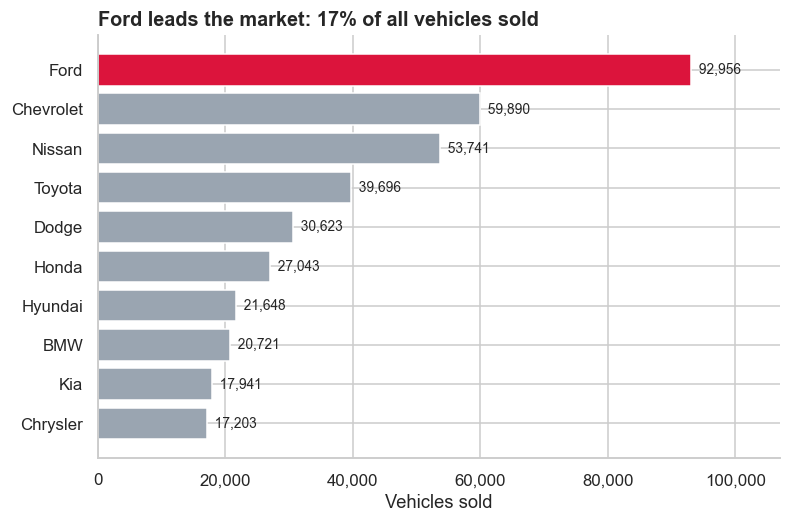

In [14]:
top_makes = df["make"].value_counts().head(10).sort_values()          # ascending, so the biggest bar ends up on top
colors = [MUTED] * (len(top_makes) - 1) + [CRIMSON]                    # highlight ONE bar

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_makes.index.astype(str), top_makes.values, color=colors)
for y, v in enumerate(top_makes.values):
    ax.text(v, y, f"  {v:,}", va="center", fontsize=9)

leader, share = top_makes.index[-1], top_makes.iloc[-1] / len(df)
ax.set_title(f"{leader} leads the market: {share:.0%} of all vehicles sold")
ax.set_xlabel("Vehicles sold")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, top_makes.max() * 1.15)
save(fig, "01_top_makes")
plt.show()

### Chart 2 · Trend → line. *How do weekly sales move over time?*

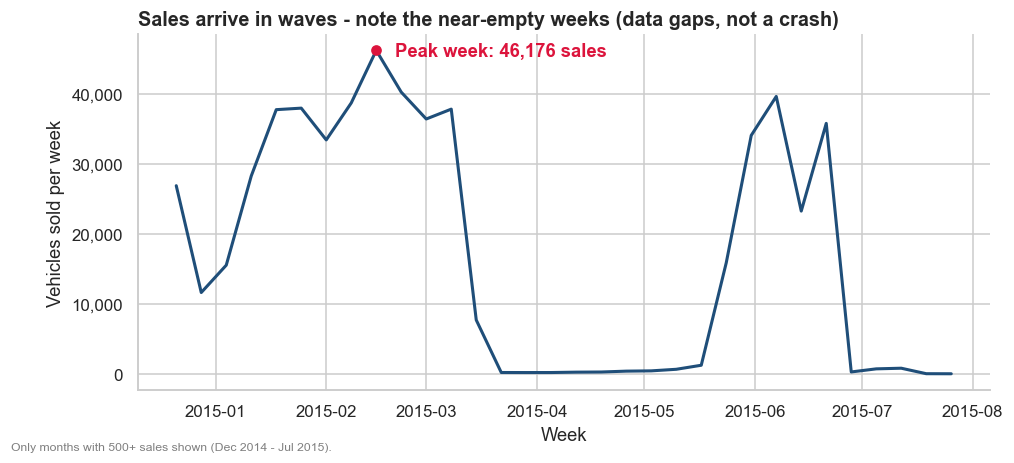

In [15]:
month_counts = df.groupby("sale_month").size()
main_months = month_counts[month_counts >= 500].index                  # ignore months with almost no data
weekly = df[df["sale_month"].isin(main_months)].set_index("saledate").resample("W").size()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(weekly.index, weekly.values, color=PRIMARY, linewidth=2)
peak_week = weekly.idxmax()
ax.scatter(peak_week, weekly.max(), color=CRIMSON, zorder=3)
ax.annotate(f"Peak week: {weekly.max():,} sales", (peak_week, weekly.max()),
            xytext=(12, -4), textcoords="offset points", color=CRIMSON, fontweight="bold")

ax.set_title("Sales arrive in waves - note the near-empty weeks (data gaps, not a crash)")
ax.set_xlabel("Week")
ax.set_ylabel("Vehicles sold per week")
ax.yaxis.set_major_formatter(thousands)
fig.text(0.01, -0.02, f"Only months with 500+ sales shown ({main_months.min():%b %Y} - {main_months.max():%b %Y}).",
         fontsize=8, color="grey")
save(fig, "02_weekly_sales")
plt.show()

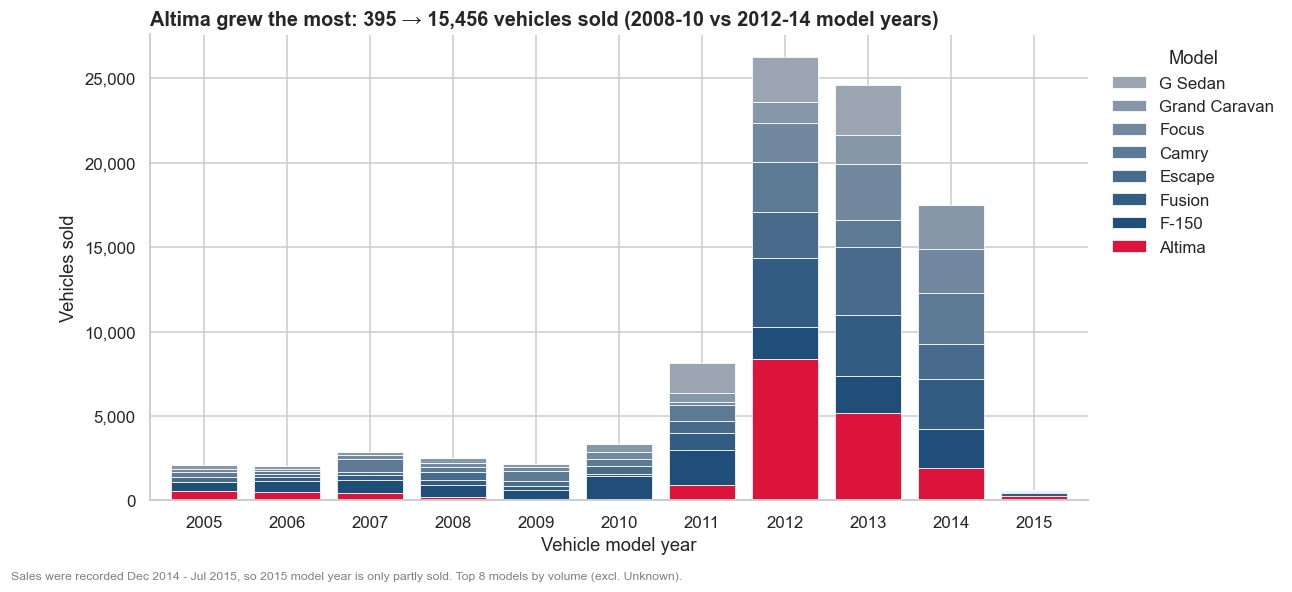

In [ ]:
# Which models grew across model years? (stacked bar)
d = df[df["year"].between(2005, 2015) & (df["model"] != "Unknown")].copy()
d["model"] = d["model"].astype(str)
top_models = d["model"].value_counts().head(8).index
d = d[d["model"].isin(top_models)]                       # compare the top models only

pivot = d.pivot_table(index="year", columns="model", values="sellingprice", aggfunc="size", fill_value=0)

# fastest grower = biggest rise between model years 2008-10 and 2012-14
early = pivot.loc[2008:2010, top_models].sum()
late = pivot.loc[2012:2014, top_models].sum()
grower = (late - early).idxmax()

others = [m for m in top_models if m != grower]
colors = dict(zip(others, sns.color_palette("blend:#1F4E79,#9AA5B1", len(others))))
colors[grower] = CRIMSON                                 # highlight ONE model in crimson
pivot = pivot[[grower] + others]                         # grower at the bottom so its growth is easy to see

fig, ax = plt.subplots(figsize=(11, 5.5))
pivot.plot(kind="bar", stacked=True, ax=ax, color=[colors[c] for c in pivot.columns],
           width=0.8, edgecolor="white", linewidth=0.5)

ax.set_title(f"{grower} grew the most: {early[grower]:,.0f} → {late[grower]:,.0f} vehicles sold (2008-10 vs 2012-14 model years)")
ax.set_xlabel("Vehicle model year")
ax.set_ylabel("Vehicles sold")
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis="x", rotation=0)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="Model", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
fig.text(0.01, -0.02, "Sales were recorded Dec 2014 - Jul 2015, so 2015 model year is only partly sold. Top 8 models by volume (excl. Unknown).",
         fontsize=8, color="grey")
save(fig, "14_models_by_year")
plt.show()

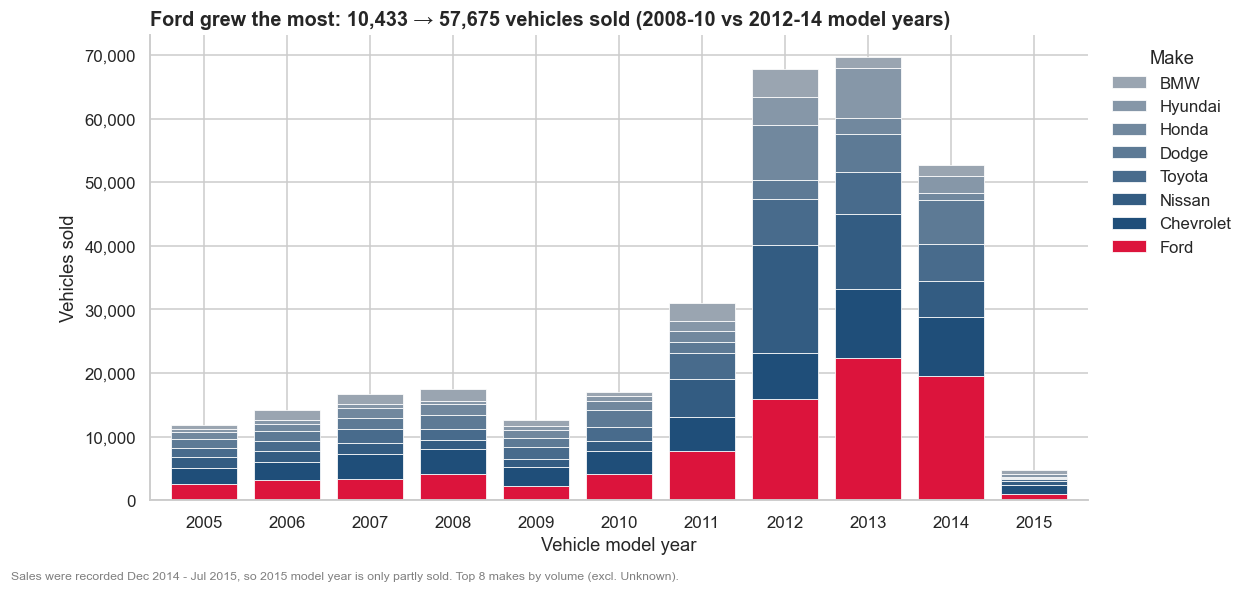

In [30]:
# Which makes grew across model years? (stacked bar)
d = df[df["year"].between(2005, 2015) & (df["make"] != "Unknown")].copy()
d["make"] = d["make"].astype(str)
top_makes = d["make"].value_counts().head(8).index
d = d[d["make"].isin(top_makes)]                         # compare the top makes only

pivot = d.pivot_table(index="year", columns="make", values="sellingprice", aggfunc="size", fill_value=0)

# fastest grower = biggest rise between model years 2008-10 and 2012-14
early = pivot.loc[2008:2010, top_makes].sum()
late = pivot.loc[2012:2014, top_makes].sum()
grower = (late - early).idxmax()

others = [m for m in top_makes if m != grower]
colors = dict(zip(others, sns.color_palette("blend:#1F4E79,#9AA5B1", len(others))))
colors[grower] = CRIMSON                                 # highlight ONE make in crimson
pivot = pivot[[grower] + others]                         # grower at the bottom so its growth is easy to see

fig, ax = plt.subplots(figsize=(11, 5.5))
pivot.plot(kind="bar", stacked=True, ax=ax, color=[colors[c] for c in pivot.columns],
           width=0.8, edgecolor="white", linewidth=0.5)

ax.set_title(f"{grower} grew the most: {early[grower]:,.0f} → {late[grower]:,.0f} vehicles sold (2008-10 vs 2012-14 model years)")
ax.set_xlabel("Vehicle model year")
ax.set_ylabel("Vehicles sold")
ax.yaxis.set_major_formatter(thousands)
ax.tick_params(axis="x", rotation=0)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="Make", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
fig.text(0.01, -0.02, "Sales were recorded Dec 2014 - Jul 2015, so 2015 model year is only partly sold. Top 8 makes by volume (excl. Unknown).",
         fontsize=8, color="grey")
save(fig, "14_makes_by_year")
plt.show()

In [31]:
import plotly.express as px
from matplotlib.colors import to_hex

counts = d.groupby(["year", "make"]).size().reset_index(name="vehicles")
fig = px.bar(counts, x="year", y="vehicles", color="make",
             category_orders={"make": [grower] + others},
             color_discrete_map={m: to_hex(c) for m, c in colors.items()},
             labels={"year": "Vehicle model year", "vehicles": "Vehicles sold", "make": "Make"},
             title=f"{grower} grew the most: {early[grower]:,.0f} → {late[grower]:,.0f} vehicles (2008-10 vs 2012-14 model years)")
fig.update_layout(xaxis=dict(dtick=1), template="plotly_white")
fig.show()

### Chart 3 · Distribution → histogram. *What do vehicles cost?*

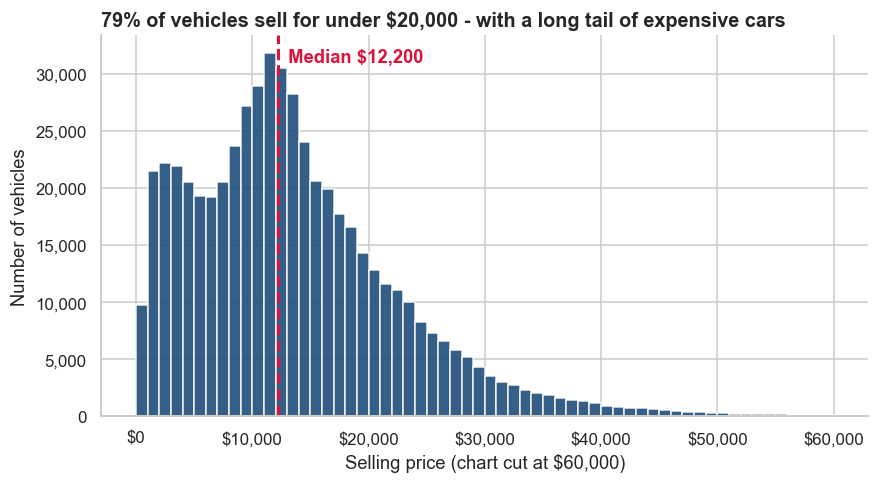

In [16]:
median_price = df["sellingprice"].median()
under_20k = (df["sellingprice"] < 20_000).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df["sellingprice"], bins=60, range=(0, 60_000), color=PRIMARY, alpha=0.9)
ax.axvline(median_price, color=CRIMSON, linestyle="--", linewidth=2)
ax.text(median_price, ax.get_ylim()[1] * 0.93, f"  Median ${median_price:,.0f}", color=CRIMSON, fontweight="bold")

ax.set_title(f"{under_20k:.0%} of vehicles sell for under $20,000 - with a long tail of expensive cars")
ax.set_xlabel("Selling price (chart cut at $60,000)")
ax.set_ylabel("Number of vehicles")
ax.xaxis.set_major_formatter(money)
ax.yaxis.set_major_formatter(thousands)
save(fig, "03_price_histogram")
plt.show()

### Chart 4 · Comparison → sorted bar. *Which body types are the most expensive?*

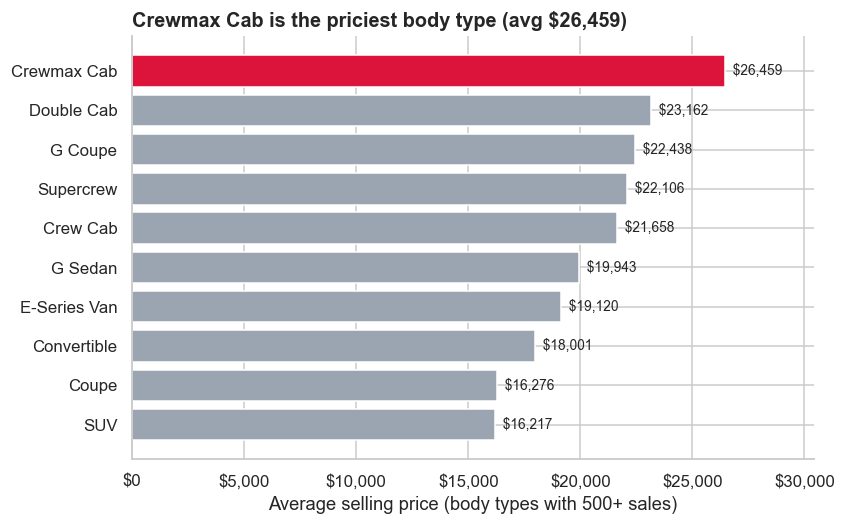

In [17]:
body = df.groupby("body", observed=True)["sellingprice"].agg(avg="mean", n="size")
body = body[body["n"] >= 500].sort_values("avg").tail(10)               # only body types with enough sales to trust

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(body.index.astype(str), body["avg"], color=[MUTED] * (len(body) - 1) + [CRIMSON])
for y, v in enumerate(body["avg"]):
    ax.text(v, y, f"  ${v:,.0f}", va="center", fontsize=9)

ax.set_title(f"{body.index[-1]} is the priciest body type (avg ${body['avg'].iloc[-1]:,.0f})")
ax.set_xlabel("Average selling price (body types with 500+ sales)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(money)
ax.set_xlim(0, body["avg"].max() * 1.15)
save(fig, "04_price_by_body")
plt.show()

### Chart 5 · Two panels side by side. *How do age and mileage show up in the price?*

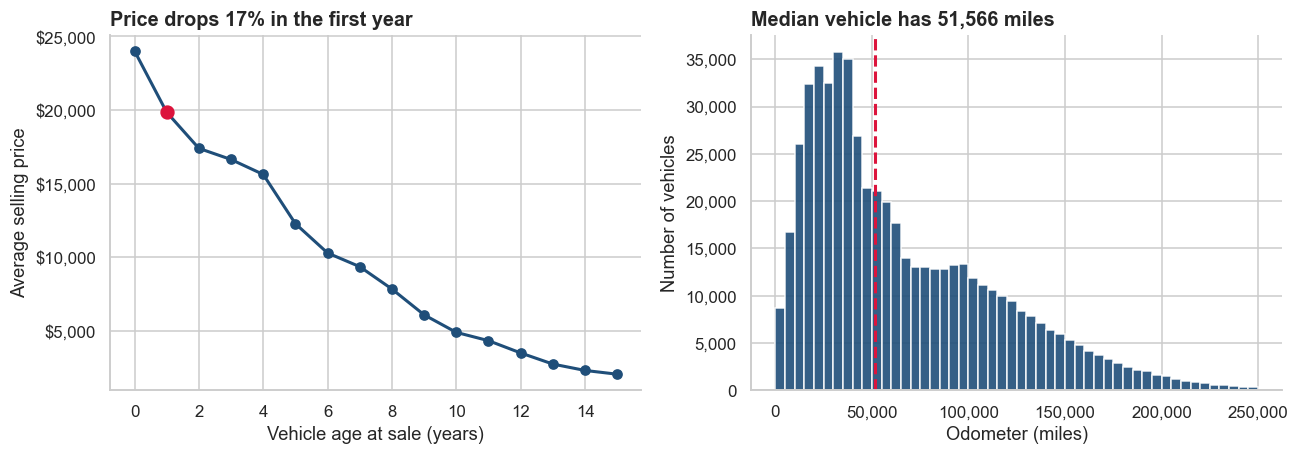

In [18]:
age = df[df["vehicle_age"] <= 15].groupby("vehicle_age")["sellingprice"].mean()
first_year_drop = 1 - age.loc[1] / age.loc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(age.index, age.values, marker="o", color=PRIMARY, linewidth=2)
ax1.scatter([1], [age.loc[1]], color=CRIMSON, zorder=3, s=70)
ax1.set_title(f"Price drops {first_year_drop:.0%} in the first year")
ax1.set_xlabel("Vehicle age at sale (years)")
ax1.set_ylabel("Average selling price")
ax1.yaxis.set_major_formatter(money)

ax2.hist(df["odometer"], bins=50, range=(0, 250_000), color=PRIMARY, alpha=0.9)
ax2.axvline(df["odometer"].median(), color=CRIMSON, linestyle="--", linewidth=2)
ax2.set_title(f"Median vehicle has {df['odometer'].median():,.0f} miles")
ax2.set_xlabel("Odometer (miles)")
ax2.set_ylabel("Number of vehicles")
ax2.xaxis.set_major_formatter(thousands)
ax2.yaxis.set_major_formatter(thousands)

fig.tight_layout()
save(fig, "05_age_and_mileage")
plt.show()

## Part 4 - seaborn: statistical charts from DataFrames in a few lines
seaborn sits on top of matplotlib. Pass the DataFrame and column names; it handles grouping, colours and legends.
(Because it *is* matplotlib underneath, you can still use `ax.set_title(...)` etc. to polish.)

### Chart 6 · Summary → box plot. *How wide is the price spread in each body type?*

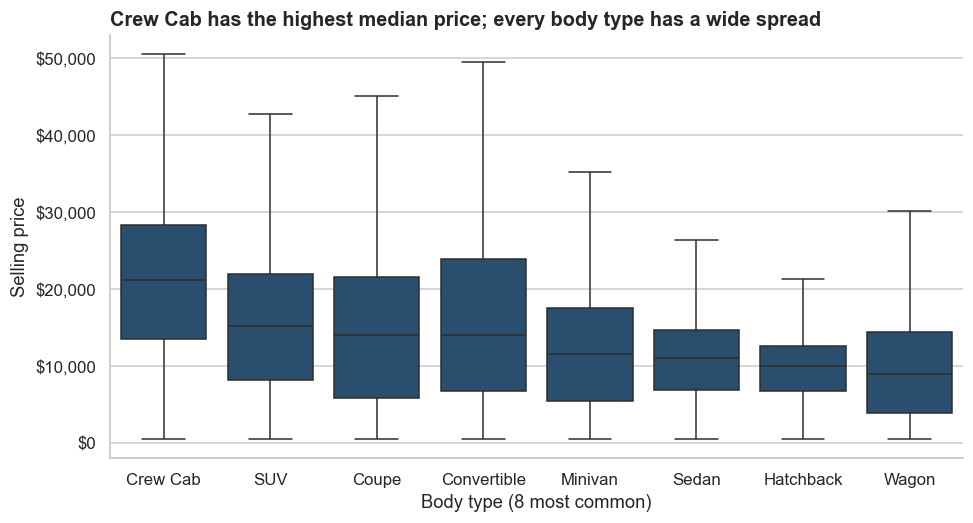

In [19]:
top_bodies = df[df["body"] != "Unknown"]["body"].value_counts().head(8).index   # skip the "Unknown" bucket
sub = df[df["body"].isin(top_bodies)].assign(body=lambda d: d["body"].astype(str))
order = sub.groupby("body")["sellingprice"].median().sort_values(ascending=False).index   # sorted by median

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=sub, x="body", y="sellingprice", order=order, color=PRIMARY, showfliers=False, ax=ax)
ax.set_title(f"{order[0]} has the highest median price; every body type has a wide spread")
ax.set_xlabel("Body type (8 most common)")
ax.set_ylabel("Selling price")
ax.yaxis.set_major_formatter(money)
save(fig, "06_price_box_by_body")
plt.show()

### Chart 7 · Correlation → scatter. *Do higher-mileage vehicles sell for less?*

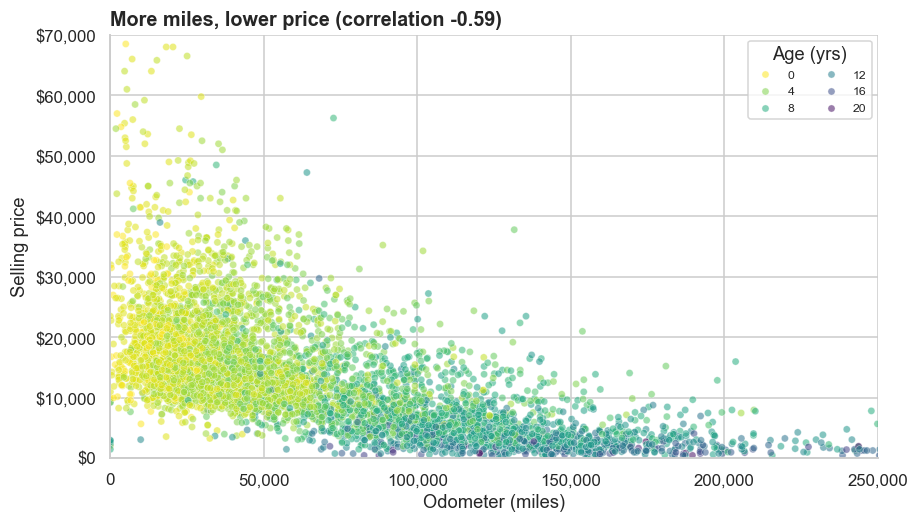

In [20]:
sample = df.sample(5_000, random_state=0)                    # 500k points would be unreadable (and slow) - plot a sample
corr = df["odometer"].corr(df["sellingprice"])

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=sample, x="odometer", y="sellingprice", hue="vehicle_age", palette="viridis_r",
                alpha=0.55, s=22, ax=ax)
ax.set_xlim(0, 250_000)
ax.set_ylim(0, 70_000)
ax.set_title(f"More miles, lower price (correlation {corr:.2f})")
ax.set_xlabel("Odometer (miles)")
ax.set_ylabel("Selling price")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(money)
ax.legend(title="Age (yrs)", fontsize=8, ncol=2, loc="upper right")
save(fig, "07_odometer_vs_price")
plt.show()

### Chart 8 · Trend by group → line. *Which brands hold their value?*

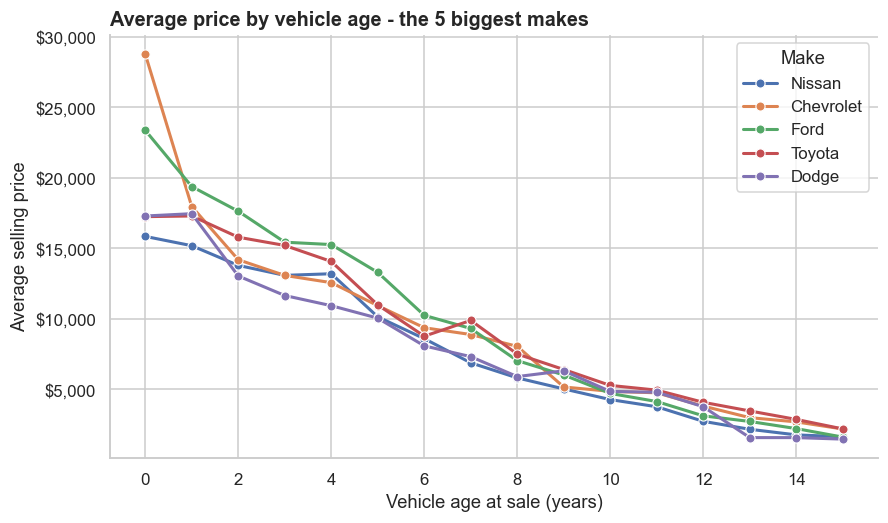

In [21]:
top5 = df["make"].value_counts().head(5).index
d = df[df["make"].isin(top5) & (df["vehicle_age"] <= 15)].assign(make=lambda x: x["make"].astype(str))

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=d, x="vehicle_age", y="sellingprice", hue="make", estimator="mean", errorbar=None,
             marker="o", linewidth=2, ax=ax)
ax.set_title("Average price by vehicle age - the 5 biggest makes")
ax.set_xlabel("Vehicle age at sale (years)")
ax.set_ylabel("Average selling price")
ax.yaxis.set_major_formatter(money)
ax.legend(title="Make")
save(fig, "08_depreciation_by_make")
plt.show()

### Chart 9 · Two categories → heatmap. *What does a 'typical' price look like by make and age?*

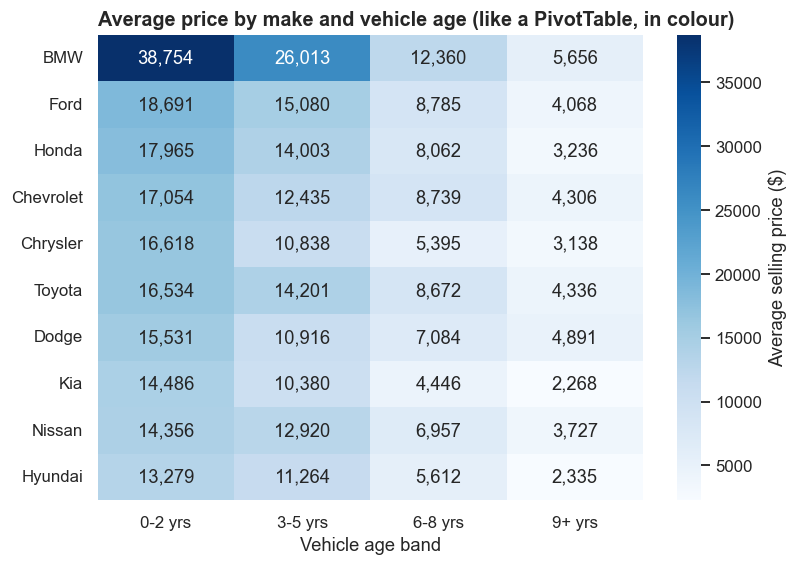

In [22]:
top10 = df["make"].value_counts().head(10).index
d = df[df["make"].isin(top10)].assign(make=lambda x: x["make"].astype(str))
d["age_band"] = pd.cut(d["vehicle_age"], [-1, 2, 5, 8, 50], labels=["0-2 yrs", "3-5 yrs", "6-8 yrs", "9+ yrs"])
pivot = (d.pivot_table(index="make", columns="age_band", values="sellingprice", aggfunc="mean", observed=True)
           .sort_values("0-2 yrs", ascending=False))

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Average selling price ($)"}, ax=ax)
ax.set_title("Average price by make and vehicle age (like a PivotTable, in colour)")
ax.set_xlabel("Vehicle age band")
ax.set_ylabel("")
save(fig, "09_price_heatmap")
plt.show()

### Chart 10 · Correlation → heatmap. *Which numeric columns move together?*

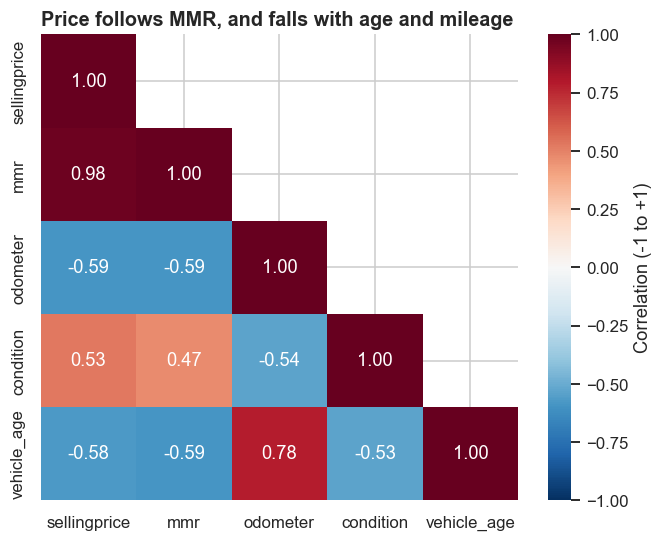

In [23]:
cols = ["sellingprice", "mmr", "odometer", "condition", "vehicle_age"]   # (year would just mirror vehicle_age)
corr_matrix = df[cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)             # hide the duplicate upper triangle

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Correlation (-1 to +1)"}, ax=ax)
ax.set_title("Price follows MMR, and falls with age and mileage")
save(fig, "10_correlation_heatmap")
plt.show()

### Chart 11 · Selling price vs. the MMR benchmark. *Do buyers pay more or less than the market guide?*

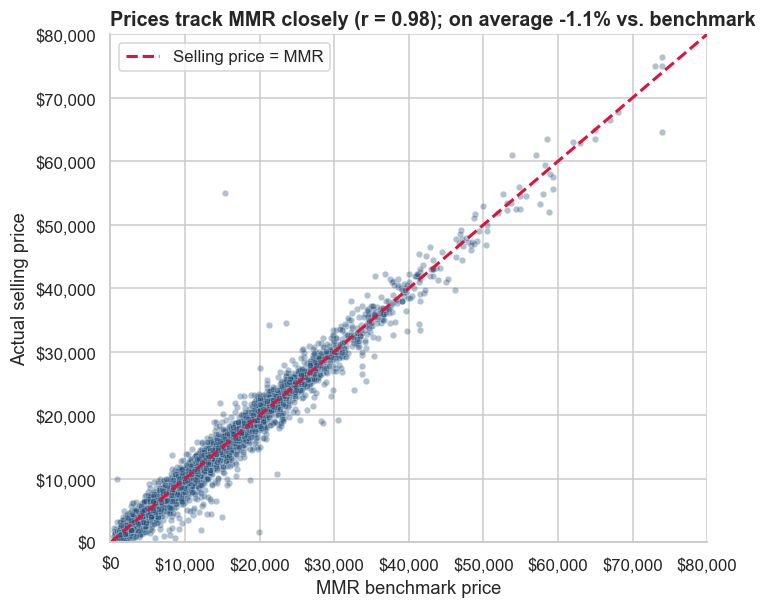

In [24]:
s = df.sample(5_000, random_state=1)
r = df["mmr"].corr(df["sellingprice"])
mean_gap = df["sellingprice"].sum() / df["mmr"].sum() - 1
lim = 80_000

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=s, x="mmr", y="sellingprice", color=PRIMARY, alpha=0.35, s=18, ax=ax)
ax.plot([0, lim], [0, lim], color=CRIMSON, linestyle="--", linewidth=2, label="Selling price = MMR")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f"Prices track MMR closely (r = {r:.2f}); on average {mean_gap:+.1%} vs. benchmark")
ax.set_xlabel("MMR benchmark price")
ax.set_ylabel("Actual selling price")
ax.xaxis.set_major_formatter(money)
ax.yaxis.set_major_formatter(money)
ax.legend()
save(fig, "11_price_vs_mmr")
plt.show()

### Chart 12 · Distribution by group → histogram. *Do manual cars sell cheaper than automatics?*

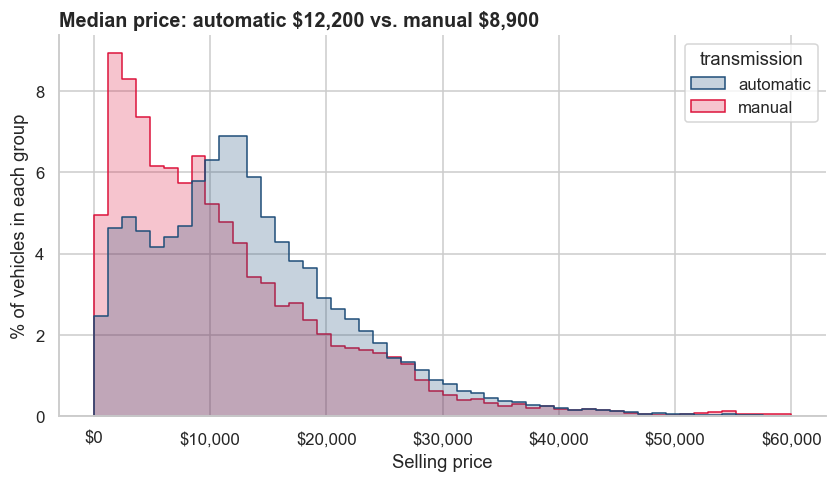

In [25]:
t = df[df["transmission"].isin(["automatic", "manual"])].assign(transmission=lambda x: x["transmission"].astype(str))
med = t.groupby("transmission")["sellingprice"].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=t, x="sellingprice", hue="transmission", stat="percent", common_norm=False, bins=50,
             binrange=(0, 60_000), element="step", palette={"automatic": PRIMARY, "manual": CRIMSON}, ax=ax)
ax.set_title(rf"Median price: automatic \${med['automatic']:,.0f} vs. manual \${med['manual']:,.0f}")   # \$ stops matplotlib reading $...$ as maths (raw f-string)
ax.set_xlabel("Selling price")
ax.set_ylabel("% of vehicles in each group")
ax.xaxis.set_major_formatter(money)
save(fig, "12_price_by_transmission")
plt.show()

### Bonus chart · Fun one - bars painted in the car colours

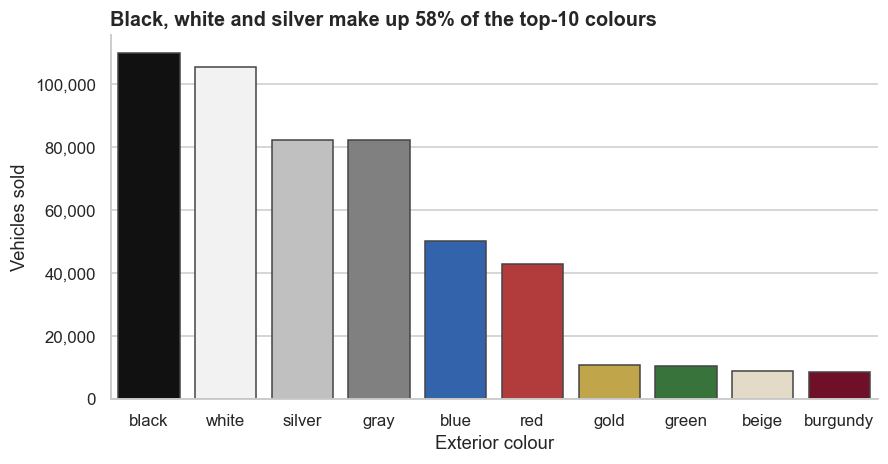

In [26]:
COLOR_MAP = {"black": "#111111", "white": "#F2F2F2", "silver": "#C0C0C0", "gray": "#808080", "blue": "#1F5FBF",
             "red": "#C62828", "green": "#2E7D32", "gold": "#D4AF37", "beige": "#E8DCC2", "burgundy": "#800020",
             "brown": "#6D4C41", "orange": "#EF6C00", "purple": "#6A1B9A", "off-white": "#FAF3E0",
             "yellow": "#FDD835", "charcoal": "#36454F", "turquoise": "#30D5C8", "pink": "#F48FB1"}
c = df["color"].astype(str).value_counts()
c = c[c.index.isin(COLOR_MAP)].head(10)                       # drop "—" and junk

fig, ax = plt.subplots(figsize=(9, 4.3))
sns.barplot(x=c.index, y=c.values, hue=c.index, palette=COLOR_MAP, legend=False, edgecolor="#444", ax=ax)
ax.set_title(f"{c.index[0].title()}, {c.index[1]} and {c.index[2]} make up {c.head(3).sum() / c.sum():.0%} of the top-10 colours")
ax.set_xlabel("Exterior colour")
ax.set_ylabel("Vehicles sold")
ax.yaxis.set_major_formatter(thousands)
save(fig, "13_colours")
plt.show()

## Part 5 - Insights, export and next steps
A chart is not finished until you can say **what it means and what to do about it**.
The cell below writes the takeaways from your *actual* numbers, so they stay correct if you filter the data.

In [27]:
k_rev = df["sellingprice"].sum()
leader = df["make"].value_counts().idxmax()
dep = df[df["vehicle_age"] <= 15].groupby("vehicle_age")["sellingprice"].mean()

print("KEY TAKEAWAYS")
print(f"1. {len(df):,} vehicles sold for ${k_rev / 1e9:,.2f}B in total; the average vehicle sold for ${df['sellingprice'].mean():,.0f}.")
print(f"2. {leader} is the #1 make ({(df['make'] == leader).mean():.0%} of sales); the top 5 makes account for {df['make'].value_counts().head(5).sum() / len(df):.0%}.")
print(f"3. A vehicle loses about {1 - dep.loc[1] / dep.loc[0]:.0%} of its value in year 1 and {1 - dep.loc[5] / dep.loc[0]:.0%} by year 5.")
print(f"4. Mileage and price move opposite ways (correlation {df['odometer'].corr(df['sellingprice']):.2f}).")
print(f"5. Vehicles sell {df['sellingprice'].sum() / df['mmr'].sum() - 1:+.1%} vs. the MMR benchmark overall.")
print("6. Data caveat: sales are concentrated in Dec 2014 - Jul 2015, so do not read seasonality from this file.")

KEY TAKEAWAYS
1. 552,247 vehicles sold for $7.60B in total; the average vehicle sold for $13,766.
2. Ford is the #1 make (17% of sales); the top 5 makes account for 50%.
3. A vehicle loses about 17% of its value in year 1 and 49% by year 5.
4. Mileage and price move opposite ways (correlation -0.59).
5. Vehicles sell -1.1% vs. the MMR benchmark overall.
6. Data caveat: sales are concentrated in Dec 2014 - Jul 2015, so do not read seasonality from this file.


In [28]:
# Save the cleaned data - this is the file the Streamlit dashboard reads (data/vehicle_sales_clean.csv.gz)
df.to_csv("vehicle_sales_clean.csv.gz", index=False)
print(f"Saved vehicle_sales_clean.csv.gz  ({os.path.getsize('vehicle_sales_clean.csv.gz') / 1e6:.1f} MB)")

# In Colab you can download it, plus all the chart PNGs, with:
# from google.colab import files; files.download("vehicle_sales_clean.csv.gz")

Saved vehicle_sales_clean.csv.gz  (15.3 MB)


### 🏋️ Practice - try it yourself
1. **Chart 1 again, but by revenue.** Which make earns the most? Is it the same as the make that sells the most vehicles?
2. **State view.** Draw a sorted bar of the top 10 states by number of vehicles. Highlight the top one in crimson.
3. **Sellers.** The raw data has a `seller` column we dropped. Add it back and chart the top 10 sellers.
4. **Condition.** Plot average price by `condition` (use `pd.cut` to make 5 bands). Does a better condition always mean a higher price?
5. **Your question.** Write one business question, pick the right chart from slide 5, and answer it with a takeaway title.

### 🚀 Next: turn this into a dashboard
Open the `vehicle_sales_dashboard/` folder: the same cleaned data, but as an **interactive Plotly + Streamlit** web app with sidebar filters, KPI cards and 4 pages. See its `README.md` for how to run and deploy it.

### 📁 Portfolio checklist (slide 19)
`Problem → Data → Cleaning → Analysis → Dashboard → Insights → Tools`: copy your answers from this notebook into your GitHub `README.md`, add the PNGs from the `charts/` folder, and link your live Streamlit app.